# Install

pip install gymnasium

In [3]:
pip install pygame

   ---------------------------------------- 0.0/10.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.6 MB 330.3 kB/s eta 0:00:33
   ---------------------------------------- 0.1/10.6 MB 656.4 kB/s eta 0:00:17
   - -------------------------------------- 0.4/10.6 MB 2.8 MB/s eta 0:00:04
   --- ------------------------------------ 0.9/10.6 MB 4.6 MB/s eta 0:00:03
   ----- ---------------------------------- 1.5/10.6 MB 6.6 MB/s eta 0:00:02
   -------- ------------------------------- 2.2/10.6 MB 7.7 MB/s eta 0:00:02
   ---------- ----------------------------- 2.7/10.6 MB 8.3 MB/s eta 0:00:01
   ------------ --------------------------- 3.4/10.6 MB 9.0 MB/s eta 0:00:01
   -------------- ------------------------- 3.9/10.6 MB 9.6 MB/s eta 0:00:01
   ----------------- ---------------------- 4.6/10.6 MB 9.7 MB/s eta 0:00:01
   ------------------- -------------------- 5.1/10.6 MB 10.1 MB/s eta 0:00:01
   -----

In [2]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


# Base Code and random player

In [5]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()


0
Number of steps : 13
1
Number of steps : 41
2
Number of steps : 36
3
Number of steps : 30
4
Number of steps : 11
5
Number of steps : 13
6
Number of steps : 20
7
Number of steps : 24
8
Number of steps : 15
9
Number of steps : 26
10
Number of steps : 30
11
Number of steps : 26
12
Number of steps : 19
13
Number of steps : 19
14
Number of steps : 15
15
Number of steps : 15
16
Number of steps : 39
17
Number of steps : 12
18
Number of steps : 9
19
Number of steps : 10
20
Number of steps : 11
21
Number of steps : 13
22
Number of steps : 16
23
Number of steps : 22
24
Number of steps : 34
25
Number of steps : 24
26
Number of steps : 31
27
Number of steps : 18
28
Number of steps : 14
29
Number of steps : 29
30
Number of steps : 29
31
Number of steps : 13
32
Number of steps : 20
33
Number of steps : 47
34
Number of steps : 13
35
Number of steps : 18
36
Number of steps : 15
37
Number of steps : 19
38
Number of steps : 20
39
Number of steps : 14
40
Number of steps : 27
41
Number of steps : 19
42


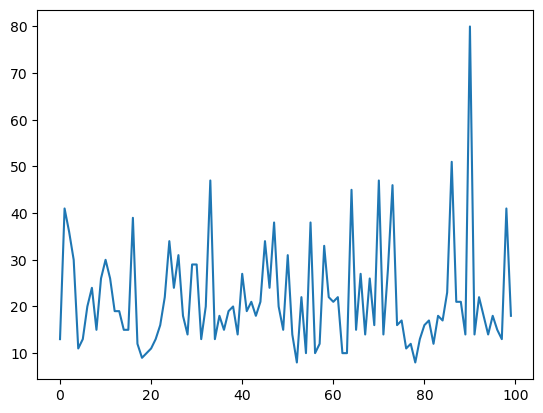

In [8]:
# exemple donné par Aleksandarhabar
episodeNumber=100
timeSteps=100
episodesResults=[]
 
for episodeIndex in range(episodeNumber):
    initial_state=env.reset()
    print(episodeIndex)
    env.render()
    appendedObservations=[]
    for timeIndex in range(timeSteps):
        random_action=env.action_space.sample()
        observation, reward, terminated, truncated, info =env.step(random_action)
        appendedObservations.append(observation)
        time.sleep(0.1)
        if (terminated):
            time.sleep(1)
            print("Number of steps :",timeIndex)
            episodesResults.append(timeIndex)
            break
print(episodesResults)
plt.plot(episodesResults)
env.close()  

# First Q learner

In [2]:
import random 
import numpy as np
from collections import defaultdict

class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        random.seed(100)
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))



In [7]:
def treatState(state):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

## With decreasing epsilon

In [19]:
episodeNumber=10000
timeSteps=10000
episodesResults=[]
qagent= Qlearning(1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

#cite johny code
 
for episodeIndex in range(episodeNumber):
    state,_=env.reset()
    state=treatState(state)
    print("episode: ",episodeIndex)
    appendedObservations=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        #print(next_state,qagent.Qvalues[tuple(next_state)],reward)
        #appendedObservations.append(observation
        qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            print("Number of steps :",timeIndex)
            episodesResults.append(timeIndex)
            break
    qagent.epsilon=max(qagent.epsilon*0.9,0.1)


env.close()  

episode:  0
Number of steps : 18
episode:  1
Number of steps : 20
episode:  2
Number of steps : 37
episode:  3
Number of steps : 17
episode:  4
Number of steps : 20
episode:  5
Number of steps : 15
episode:  6
Number of steps : 18
episode:  7
Number of steps : 21
episode:  8
Number of steps : 17
episode:  9
Number of steps : 16
episode:  10
Number of steps : 20
episode:  11
Number of steps : 15
episode:  12
Number of steps : 12
episode:  13
Number of steps : 16
episode:  14
Number of steps : 25
episode:  15
Number of steps : 26
episode:  16
Number of steps : 11
episode:  17
Number of steps : 15
episode:  18
Number of steps : 16
episode:  19
Number of steps : 11
episode:  20
Number of steps : 16
episode:  21
Number of steps : 25
episode:  22
Number of steps : 13
episode:  23
Number of steps : 16
episode:  24
Number of steps : 15
episode:  25
Number of steps : 15
episode:  26
Number of steps : 13
episode:  27
Number of steps : 13
episode:  28
Number of steps : 10
episode:  29
Number of s

173.1747


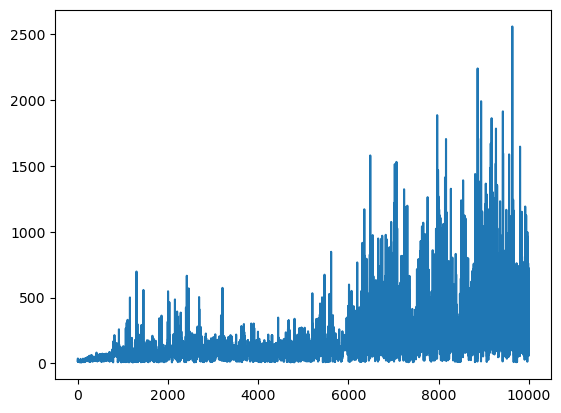

In [20]:
plt.plot(episodesResults)
print(sum(episodesResults)/len(episodesResults))

## Without decreasing Epsilon

In [26]:
episodeNumber=10000
timeSteps=10000
episodesResults=[]
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

#cite johny code
 
for episodeIndex in range(episodeNumber):
    state,_=env.reset()
    state=treatState(state)
    print("episode: ",episodeIndex)
    appendedObservations=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        #print(next_state,qagent.Qvalues[tuple(next_state)],reward)
        #appendedObservations.append(observation
        qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            print("Number of steps :",timeIndex)
            episodesResults.append(timeIndex)
            break
    


env.close()  

episode:  0
Number of steps : 9
episode:  1
Number of steps : 9
episode:  2
Number of steps : 8
episode:  3
Number of steps : 7
episode:  4
Number of steps : 9
episode:  5
Number of steps : 8
episode:  6
Number of steps : 8
episode:  7
Number of steps : 8
episode:  8
Number of steps : 10
episode:  9
Number of steps : 7
episode:  10
Number of steps : 8
episode:  11
Number of steps : 8
episode:  12
Number of steps : 8
episode:  13
Number of steps : 10
episode:  14
Number of steps : 8
episode:  15
Number of steps : 8
episode:  16
Number of steps : 9
episode:  17
Number of steps : 11
episode:  18
Number of steps : 7
episode:  19
Number of steps : 9
episode:  20
Number of steps : 8
episode:  21
Number of steps : 9
episode:  22
Number of steps : 7
episode:  23
Number of steps : 8
episode:  24
Number of steps : 7
episode:  25
Number of steps : 8
episode:  26
Number of steps : 10
episode:  27
Number of steps : 9
episode:  28
Number of steps : 8
episode:  29
Number of steps : 8
episode:  30
Num

159.7126
9


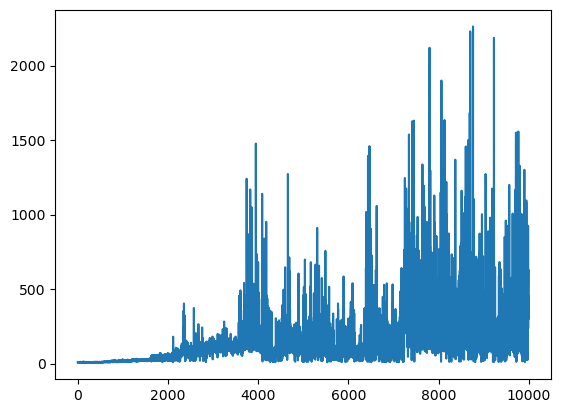

In [29]:
plt.plot(episodesResults)
print(sum(episodesResults)/len(episodesResults))
print(min(episodesResults[9000:]))

(array([15., 18., 14., 13., 14., 23., 35., 49., 40., 37., 31., 21., 14.,
        19., 12., 12., 18., 14., 19., 21., 31., 34., 26., 35., 28., 30.,
        22., 12., 24., 12., 11., 12., 14., 12.,  7.,  9., 10., 14., 13.,
         7., 13.,  4., 10.,  8.,  6.,  8.,  7.,  8.,  9., 11.,  8.,  7.,
         3.,  6.,  6.,  4.,  5.,  6.,  5.,  0.,  3.,  4.,  1.,  2.,  1.,
         1.,  3.,  2.,  2.,  3.,  5.,  1.,  1.,  1.,  0.,  1.,  0.,  4.,
         1.,  1.,  2.,  0.,  1.,  0.,  2.,  0.,  0.,  2.,  0.,  1.,  0.,
         2.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  2.,  0.,  0.,  1.,  1.,
         1.,  0.,  1.,  1.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,
         0.,  1.,  0.,  1.,  1.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  2.,  1.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.

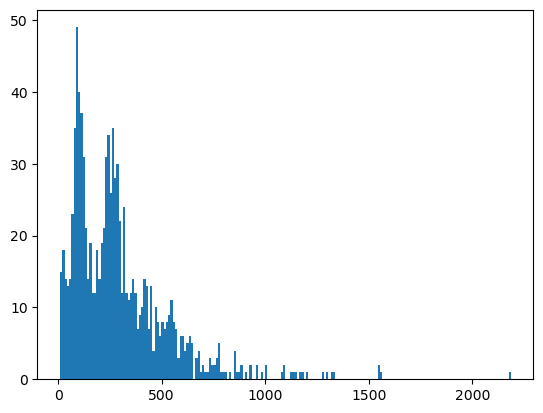

In [34]:
plt.hist(episodesResults[9000:], 200)

# Episodique reward

This is one of the first steps to making a distribution based reward. Because the final rewards of an episode must ressemble to the result of the episode.

In [6]:
import random 
import numpy as np
from collections import defaultdict
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        random.seed(100)
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],-1)
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],1)

In [13]:
episodeNumber=10000
timeSteps=10000
episodesResults=[]
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

#cite johny code
 
for episodeIndex in range(episodeNumber):
    state,_=env.reset()
    state=treatState(state)
    print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        #print(next_state,qagent.Qvalues[tuple(next_state)],reward)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            print("Number of steps :",timeIndex)
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation)
    


env.close()  

episode:  0
Number of steps : 9
episode:  1
Number of steps : 8
episode:  2
Number of steps : 10
episode:  3
Number of steps : 8
episode:  4
Number of steps : 8
episode:  5
Number of steps : 8
episode:  6
Number of steps : 10
episode:  7
Number of steps : 10
episode:  8
Number of steps : 9
episode:  9
Number of steps : 9
episode:  10
Number of steps : 10
episode:  11
Number of steps : 8
episode:  12
Number of steps : 9
episode:  13
Number of steps : 10
episode:  14
Number of steps : 10
episode:  15
Number of steps : 9
episode:  16
Number of steps : 8
episode:  17
Number of steps : 9
episode:  18
Number of steps : 8
episode:  19
Number of steps : 8
episode:  20
Number of steps : 8
episode:  21
Number of steps : 9
episode:  22
Number of steps : 8
episode:  23
Number of steps : 9
episode:  24
Number of steps : 10
episode:  25
Number of steps : 9
episode:  26
Number of steps : 8
episode:  27
Number of steps : 13
episode:  28
Number of steps : 9
episode:  29
Number of steps : 9
episode:  30

297.6934
9


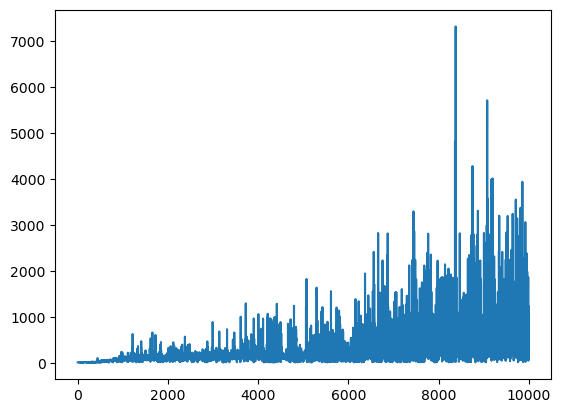

In [14]:
plt.plot(episodesResults)
print(sum(episodesResults)/len(episodesResults))
print(min(episodesResults[9000:]))

## Now add action number to state

We must modify the treatStatefunction to add the action number of the state. \
This could be useful to differentiate to actions at different time in an episode

In [4]:
def treatState(state,actionNumber):
    new_state=[]
    new_state.append(np.digitize(state[0],pos_space))
    new_state.append(np.digitize(state[1],vel_space))
    new_state.append(np.digitize(state[2],ang_space))
    new_state.append(np.digitize(state[3],ang_vel_space))
    new_state.append(actionNumber//10)
    #new_state.append(actionNumber)
    """state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    state.append(actionNumber)"""
   
    return new_state

In [81]:
episodeNumber=10000
timeSteps=10000
episodesResults=[]
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

#cite johny code
 
for episodeIndex in range(episodeNumber):
    state,_=env.reset()
    state=treatState(state,0)
    print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state,timeIndex+1)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            print("Number of steps :",timeIndex)
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation)
    


env.close()  

episode:  0
Number of steps : 9
episode:  1
Number of steps : 7
episode:  2
Number of steps : 7
episode:  3
Number of steps : 8
episode:  4
Number of steps : 9
episode:  5
Number of steps : 8
episode:  6
Number of steps : 8
episode:  7
Number of steps : 9
episode:  8
Number of steps : 8
episode:  9
Number of steps : 8
episode:  10
Number of steps : 9
episode:  11
Number of steps : 12
episode:  12
Number of steps : 9
episode:  13
Number of steps : 8
episode:  14
Number of steps : 8
episode:  15
Number of steps : 8
episode:  16
Number of steps : 7
episode:  17
Number of steps : 8
episode:  18
Number of steps : 8
episode:  19
Number of steps : 9
episode:  20
Number of steps : 9
episode:  21
Number of steps : 8
episode:  22
Number of steps : 12
episode:  23
Number of steps : 8
episode:  24
Number of steps : 8
episode:  25
Number of steps : 8
episode:  26
Number of steps : 9
episode:  27
Number of steps : 8
episode:  28
Number of steps : 12
episode:  29
Number of steps : 9
episode:  30
Numb

In [9]:
plt.plot(episodesResults)
print(sum(episodesResults)/len(episodesResults))
print(min(episodesResults[9000:]))

NameError: name 'episodesResults' is not defined

The performance become very bad if we add the action number to the state

# New reward

First try at making a reward system that tend to a certain level and not perpetually increassing.

In [18]:
goal=80

In [53]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        random.seed(100)
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],goal - abs(goal-result))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],goal - abs(goal-result))

In [94]:
episodeNumber=10000
timeSteps=10000
episodesResults=[]
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

#cite johny code
 
for episodeIndex in range(episodeNumber):
    state,_=env.reset()
    state=treatState(state)
    print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            print("Number of steps :",timeIndex)
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation)
    


env.close()  

episode:  0
Number of steps : 9
episode:  1
Number of steps : 9
episode:  2
Number of steps : 9
episode:  3
Number of steps : 9
episode:  4
Number of steps : 8
episode:  5
Number of steps : 9
episode:  6
Number of steps : 8
episode:  7
Number of steps : 8
episode:  8
Number of steps : 8
episode:  9
Number of steps : 8
episode:  10
Number of steps : 10
episode:  11
Number of steps : 7
episode:  12
Number of steps : 8
episode:  13
Number of steps : 9
episode:  14
Number of steps : 8
episode:  15
Number of steps : 11
episode:  16
Number of steps : 8
episode:  17
Number of steps : 7
episode:  18
Number of steps : 8
episode:  19
Number of steps : 8
episode:  20
Number of steps : 10
episode:  21
Number of steps : 9
episode:  22
Number of steps : 8
episode:  23
Number of steps : 7
episode:  24
Number of steps : 9
episode:  25
Number of steps : 8
episode:  26
Number of steps : 9
episode:  27
Number of steps : 9
episode:  28
Number of steps : 13
episode:  29
Number of steps : 9
episode:  30
Num

85.089


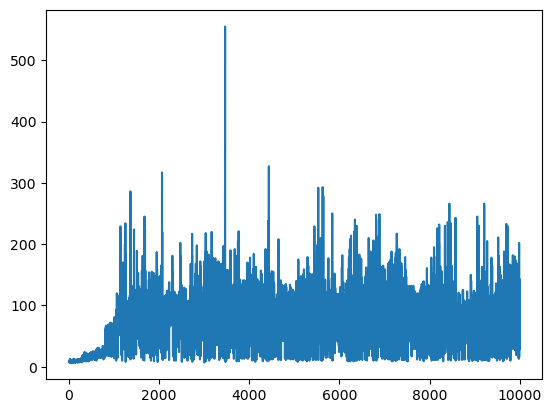

In [96]:
plt.plot(episodesResults)
print(sum(episodesResults)/len(episodesResults))

# Test graph

In [9]:
goal=80

In [54]:
episodeNumber=10000
timeSteps=10000
episodesResults=[]
episodesTestResults=[]
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

#cite johny code
 
for episodeIndex in range(episodeNumber):
    if(episodeIndex %500 ==0):
        qagent.epsilon=0
    else:
        qagent.epsilon=0.1
    state,_=env.reset()
    state=treatState(state)
    print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            print("Number of steps :",timeIndex)
            if(episodeIndex %500 ==0):
                episodesTestResults.append(timeIndex)
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation)
    


env.close()  

episode:  0
Number of steps : 8
episode:  1
Number of steps : 7
episode:  2
Number of steps : 7
episode:  3
Number of steps : 11
episode:  4
Number of steps : 7
episode:  5
Number of steps : 9
episode:  6
Number of steps : 8
episode:  7
Number of steps : 7
episode:  8
Number of steps : 7
episode:  9
Number of steps : 8
episode:  10
Number of steps : 8
episode:  11
Number of steps : 13
episode:  12
Number of steps : 13
episode:  13
Number of steps : 8
episode:  14
Number of steps : 9
episode:  15
Number of steps : 10
episode:  16
Number of steps : 8
episode:  17
Number of steps : 8
episode:  18
Number of steps : 9
episode:  19
Number of steps : 8
episode:  20
Number of steps : 8
episode:  21
Number of steps : 12
episode:  22
Number of steps : 7
episode:  23
Number of steps : 9
episode:  24
Number of steps : 7
episode:  25
Number of steps : 7
episode:  26
Number of steps : 7
episode:  27
Number of steps : 8
episode:  28
Number of steps : 10
episode:  29
Number of steps : 9
episode:  30
N

87.8993


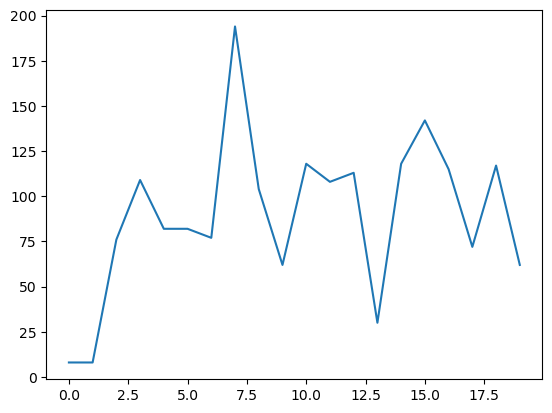

In [55]:
plt.plot(episodesTestResults)
print(sum(episodesResults)/len(episodesResults))

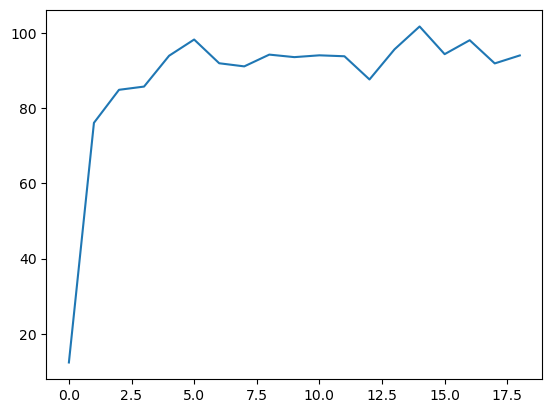

In [56]:
previous100AveragePlot=[]
for i in range(1,len(episodesTestResults)):
    previous100AveragePlot.append(sum(episodesResults[(i*500)-100:(i*500)])/100)

plt.plot(previous100AveragePlot)

Other test of reward but not good

In [ ]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        random.seed(100)
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],goal - abs(goal-result)/goal)
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],goal - abs(goal-result)/goal )

Test with higher point difference, closer to goal give much more points

In [57]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        random.seed(100)
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))

In [10]:
episodeNumber=10000
timeSteps=10000
episodesResults=[]
episodesTestResults=[]
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

#cite johny code
 
for episodeIndex in range(episodeNumber):
    if(episodeIndex %500 ==0):
        qagent.epsilon=0
    else:
        qagent.epsilon=0.1
    state,_=env.reset()
    state=treatState(state)
    #print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            #print("Number of steps :",timeIndex)
            if(episodeIndex %500 ==0):
                episodesTestResults.append(timeIndex)
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation)
    


env.close() 

75.9359


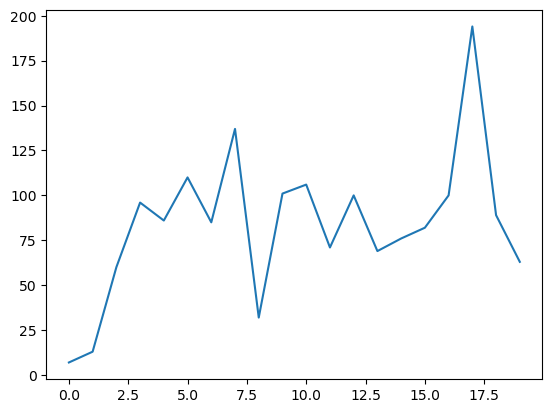

In [59]:
plt.plot(episodesTestResults)
print(sum(episodesResults)/len(episodesResults))

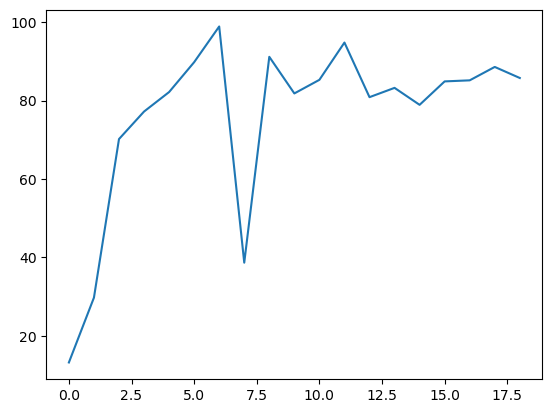

In [61]:
previous100AveragePlot=[]
for i in range(1,len(episodesTestResults)):
    previous100AveragePlot.append(sum(episodesResults[(i*500)-100:(i*500)])/100)

plt.plot(previous100AveragePlot)

### Apply 10 % decrease on goal

In [2]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        random.seed(100)
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(int(goal*9/10) - abs(goal-result) ))

In [ ]:
episodeNumber=10000
timeSteps=10000
episodesResults=[]
episodesTestResults=[]
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

In [19]:
goal=130

In [23]:


#cite johny code
 
for episodeIndex in range(episodeNumber):
    if(episodeIndex %500 ==0):
        qagent.epsilon=0
    else:
        qagent.epsilon=0.1
    state,_=env.reset()
    state=treatState(state)
    #print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            #print("Number of steps :",timeIndex)
            if(episodeIndex %500 ==0):
                episodesTestResults.append(timeIndex)
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation)
    


env.close() 

96.1156


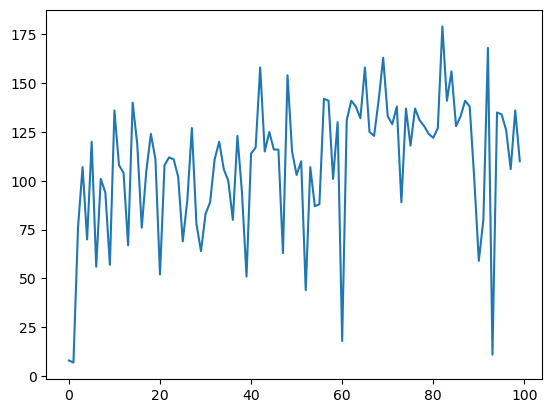

In [24]:
plt.plot(episodesTestResults)
print(sum(episodesResults)/len(episodesResults))

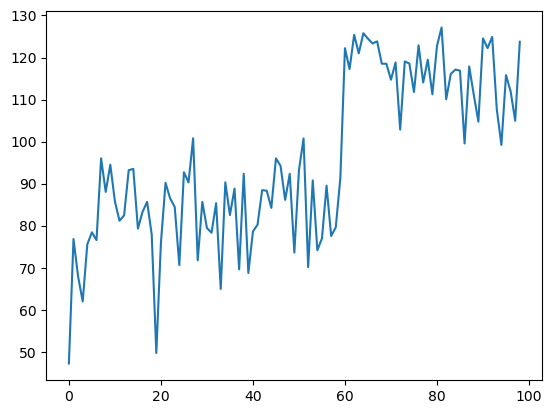

In [25]:
previous100AveragePlot=[]
for i in range(1,len(episodesTestResults)):
    previous100AveragePlot.append(sum(episodesResults[(i*500)-100:(i*500)])/100)

plt.plot(previous100AveragePlot)

Test with multiple times same agent retrained\
- Retraining after changing goal cause a slower ascent to goal, retraining from beigining seems better\
- training multiple times after obtained acceptable result doesn't seem much better great variation, idea : maybe tune down training when goal start to look good